In [1]:
!pip install tensorflow-datasets
import tensorflow_datasets as tfds
# Load the dataset with supervised labels
(train_set, test_set), info = tfds.load(
   'cats_vs_dogs',
   split=['train[:80%]', 'train[80%:]'], # 80% training, 20% testing
   as_supervised=True, # Returns (image, label) pairs
   with_info=True # Includes dataset metadata
)
# Display dataset information
print(info)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.1/327.1 kB 3.8 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.20.0
    Uninstalling protobuf-3.20.0:
      Successfully uninstalled protobuf-3.20.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.35.1 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.35.1 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.35.1 which is incompatible.


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.IE6P0M_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='cats_vs_dogs',
    full_name='cats_vs_dogs/4.0.1',
    description="""
    A large set of images of cats and dogs. There are 1738 corrupted images that are dropped.
    """,
    homepage='https://www.microsoft.com/en-us/download/details.aspx?id=54765',
    data_dir='/root/tensorflow_datasets/cats_vs_dogs/4.0.1',
    file_format=tfrecord,
    download_size=786.67 MiB,
    dataset_size=1.04 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=23262, num_shards=16>,
    },
    citation="""@Inproceedings 

In [2]:
#PRE-PROCESS
import tensorflow as tf
IMG_SIZE = (150, 150)
def preprocess(image, label):
   image = tf.image.resize(image, IMG_SIZE) / 255.0 # Normalize to [0, 1]
   return image, label
train_set = train_set.map(preprocess).batch(32).prefetch(tf.data.AUTOTUNE)
test_set = test_set.map(preprocess).batch(32).prefetch(tf.data.AUTOTUNE)

In [5]:
train_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

CATS - 0
DOGS - 1

Shape of image batch: (32, 150, 150, 3)
Shape of label batch: (32,)


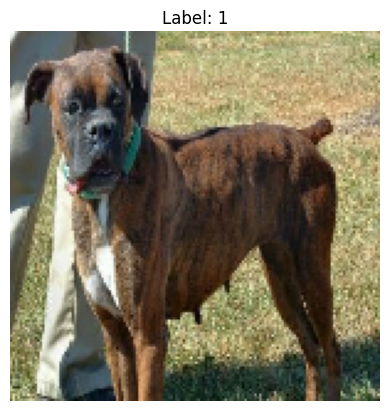

In [8]:
# To inspect elements of a tf.data.Dataset, you need to iterate over it.
# Here's how to get the first batch:
for image_batch, label_batch in train_set.take(1):
    print(f"Shape of image batch: {image_batch.shape}")
    print(f"Shape of label batch: {label_batch.shape}")
    # Display the first image in the batch
    import matplotlib.pyplot as plt
    plt.imshow(image_batch[0].numpy())
    plt.title(f"Label: {label_batch[0].numpy()}")
    plt.axis('off')
    plt.show()
    break # We only want the first batch

In [9]:
from tensorflow.keras import layers, models
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [11]:
model.fit(train_set, validation_data=test_set, epochs=5)

Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 417s 712ms/step - accuracy: 0.6818 - loss: 0.5906 - val_accuracy: 0.7425 - val_loss: 0.5187
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 401s 689ms/step - accuracy: 0.7881 - loss: 0.4512 - val_accuracy: 0.7500 - val_loss: 0.5059
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 432s 671ms/step - accuracy: 0.8476 - loss: 0.3486 - val_accuracy: 0.7635 - val_loss: 0.5558
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 401s 689ms/step - accuracy: 0.8942 - loss: 0.2518 - val_accuracy: 0.7698 - val_loss: 0.6427
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 428s 665ms/step - accuracy: 0.9257 - loss: 0.1810 - val_accuracy: 0.7620 - val_loss: 0.7859


In [30]:
model.save('cats_vs_dogs_classifier.keras')
print("Model saved as 'cats_vs_dogs_classifier.keras'")

Model saved as 'cats_vs_dogs_classifier.keras'


VISULAIZING THE CONV2D AND MAXSPOOLING

In [15]:
from tensorflow.keras.models import Model
from tensorflow.keras import Input

# Define a new Input layer that matches the model's expected input shape
input_tensor_for_extraction = Input(shape=(150, 150, 3))

# Pass the new input tensor through the first few layers of the original model
conv_output_tensor = model.layers[0](input_tensor_for_extraction)
pool_output_tensor = model.layers[1](conv_output_tensor)

activation_model = Model(
    inputs=input_tensor_for_extraction,
    outputs=[conv_output_tensor, pool_output_tensor]
)

In [17]:
for images, labels in train_set.take(1):
    image = images[0]   # First image in the batch
    break

In [18]:
print(image.shape)

(150, 150, 3)


In [19]:
image_batch = tf.expand_dims(image, axis=0)

In [20]:
print(image_batch.shape)

(1, 150, 150, 3)


In [21]:
conv_output, pool_output = activation_model.predict(image_batch)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


In [22]:
print(conv_output.shape)
print(pool_output.shape)

(1, 148, 148, 32)
(1, 74, 74, 32)


VISUALIZING

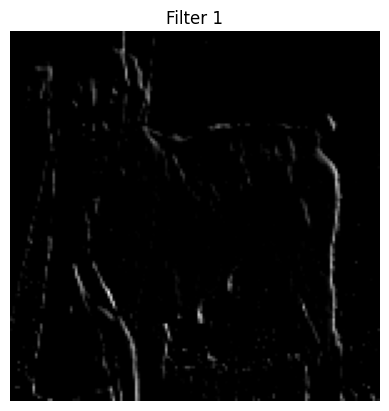

In [25]:
import matplotlib.pyplot as plt

plt.imshow(conv_output[0, :, :, 0], cmap="gray")
plt.title("Filter 1")
plt.axis("off")
plt.show()

In [27]:
conv_output[0, :, :, 0]

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.04244018, 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.17313515, 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.13525355, 0.02339343,
        0.04851715]], dtype=float32)

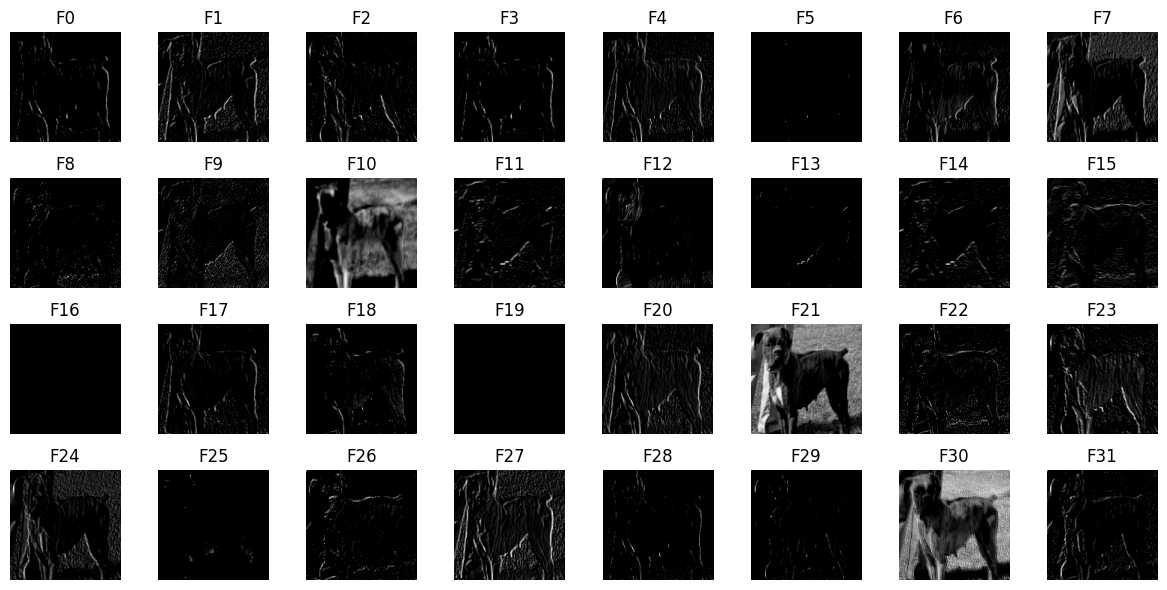

In [28]:
fig, axes = plt.subplots(4, 8, figsize=(12,6))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv_output[0, :, :, i], cmap="gray")
    ax.set_title(f"F{i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

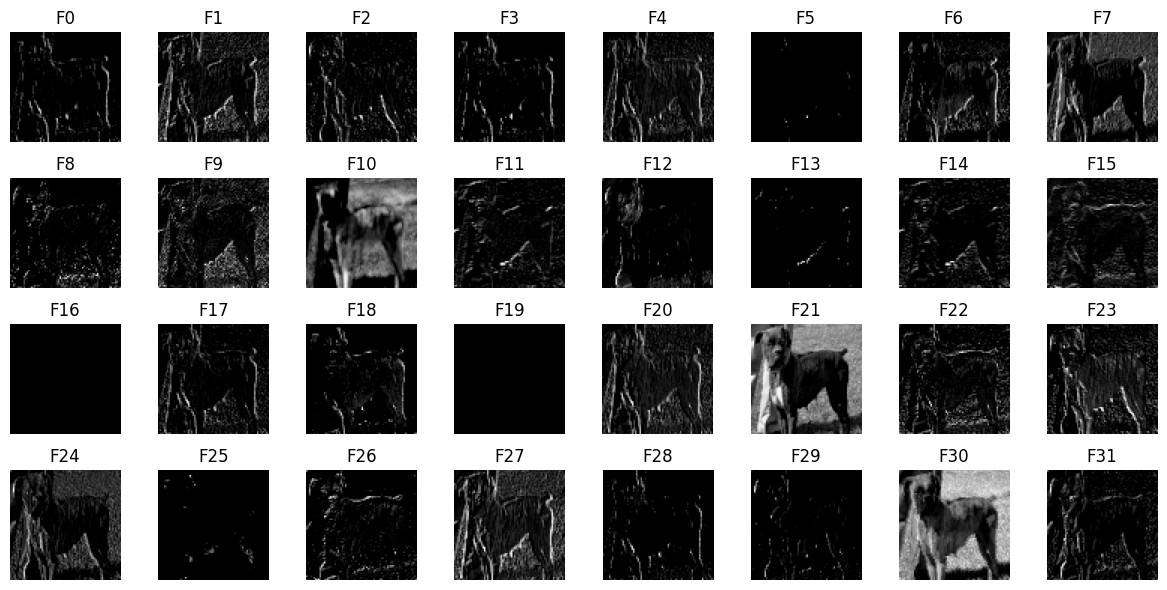

In [29]:
fig, axes = plt.subplots(4, 8, figsize=(12,6))

for i, ax in enumerate(axes.flat):
    ax.imshow(pool_output[0, :, :, i], cmap="gray")
    ax.set_title(f"F{i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

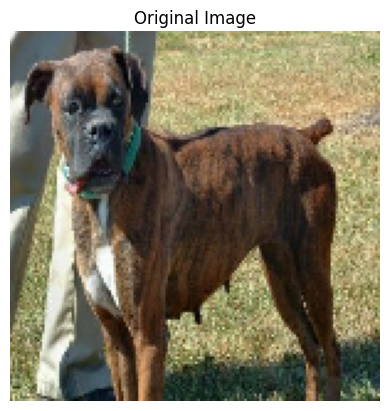

In [26]:
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [32]:
predictions = model.predict(image_batch)
print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
[[0.9999733]]
